In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [3]:
ai_measurements_df = pd.read_excel('AI_Research_Technical_Outputs.xlsx')

In [4]:
non_zero_usage = ai_measurements_df[ai_measurements_df['Usage Rate'] > ai_measurements_df['Usage Rate'].quantile(0.75)]

In [5]:
ai_measurements_df['AIOE'].rank(pct=True)

0      0.001862
1      0.003724
2      0.007449
3      0.013035
4      0.033520
         ...   
532    0.083799
533    0.271881
534    0.197393
535    0.262570
536    0.182495
Name: AIOE, Length: 537, dtype: float64

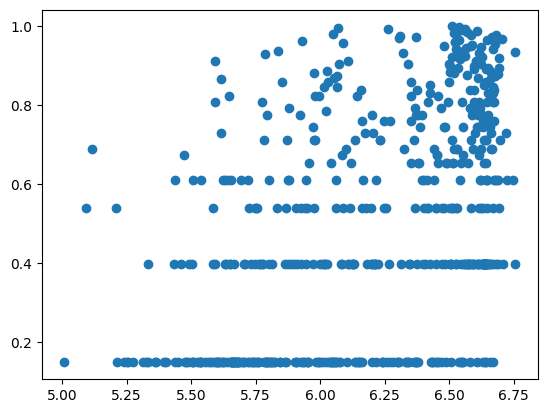

In [6]:
#non_zero_usage = ai_measurements_df[ai_measurements_df['Usage Rate'] > 0]
plt.scatter(ai_measurements_df['AIOE'], ai_measurements_df['Usage Rate'].rank(pct=True))

# plt.scatter(ai_measurements_df['AIOE'], ai_measurements_df['Usage Rate'])

Text(0, 0.5, 'actual with line on (nonzero) median')

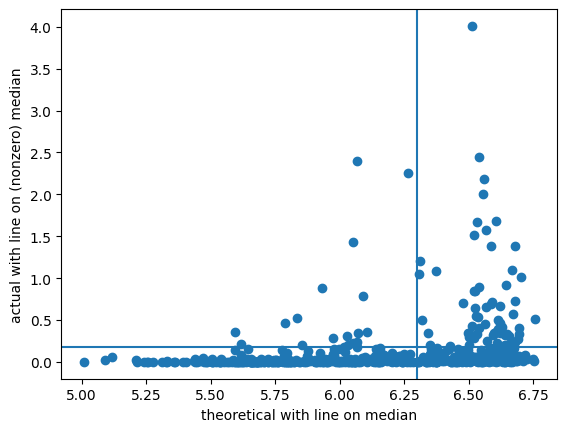

In [7]:
plt.scatter(ai_measurements_df['AIOE'], ai_measurements_df['Usage Rate'])
plt.axhline(non_zero_usage['Observed Exposure'].median())
plt.axvline(ai_measurements_df['AIOE'].median())

plt.xlabel('theoretical with line on median')
plt.ylabel('actual with line on (nonzero) median')

Text(0, 0.5, 'actual with line on (nonzero) median')

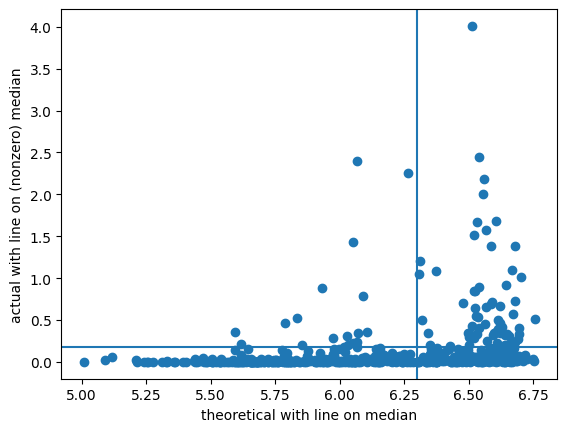

In [8]:
plt.scatter(ai_measurements_df['AIOE'], ai_measurements_df['Usage Rate'])
plt.axhline(non_zero_usage['Observed Exposure'].median())
plt.axvline(ai_measurements_df['AIOE'].median())

plt.xlabel('theoretical with line on median')
plt.ylabel('actual with line on (nonzero) median')

In [9]:
ai_measurements_df.select_dtypes(include='number').corr()['AIOE']

AIOE                    1.000000
Complementarity        -0.096294
C-AIOE                  0.604446
LLM Rating Beta         0.762611
Human Rating Beta       0.801604
Usage Rate              0.214264
Observed Exposure       0.475328
Augmentation Percent    0.414211
Automation Percent     -0.414218
AIOE Percentile         0.975851
MCA_entry_count         0.011205
Name: AIOE, dtype: float64

In [10]:
ai_measurements_df.select_dtypes(include='number').corr()['AIOE']

AIOE                    1.000000
Complementarity        -0.096294
C-AIOE                  0.604446
LLM Rating Beta         0.762611
Human Rating Beta       0.801604
Usage Rate              0.214264
Observed Exposure       0.475328
Augmentation Percent    0.414211
Automation Percent     -0.414218
AIOE Percentile         0.975851
MCA_entry_count         0.011205
Name: AIOE, dtype: float64

In [13]:
ai_measurements_df.select_dtypes(include='number')

,AIOE,Complementarity,C-AIOE,LLM Rating Beta,Human Rating Beta,Usage Rate,Observed Exposure,Augmentation Percent,Automation Percent,AIOE Percentile,MCA_entry_count
0,5.008307,41.270833,4.837189,0.024390,0.024390,0.00,0.0000,34.38,65.63,0.001862,0
1,5.090957,53.270833,4.306101,0.142857,0.071429,0.02,0.0203,45.79,54.21,0.003724,2
2,5.210569,52.979167,4.422471,0.000000,0.000000,0.02,0.0000,24.61,75.39,0.007449,0
3,5.253395,56.041667,4.297934,0.027027,0.000000,0.00,0.0000,62.96,37.04,0.013035,0
4,5.433540,51.729167,4.679636,0.117647,0.044118,0.01,0.0000,52.22,47.78,0.033520,0
...,...,...,...,...,...,...,...,...,...,...,...
532,5.591587,77.645833,3.366601,0.110000,0.110000,0.01,0.0000,2.45,97.55,0.083799,0
533,5.885910,80.020833,3.404018,0.400000,0.200000,0.01,0.0296,25.78,74.22,0.271881,1
534,5.756917,79.166667,3.378591,0.166667,0.145833,0.00,0.0913,31.78,68.22,0.197393,3
535,5.873208,80.041667,3.395449,0.279070,0.406977,0.07,0.0531,55.58,44.42,0.262570,0


Text(0, 0.5, 'augmentation with line on (nonzero) median')

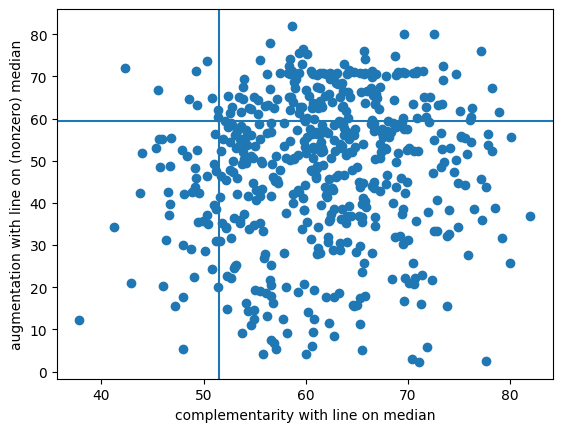

In [14]:
plt.scatter(ai_measurements_df['Complementarity'], ai_measurements_df['Augmentation Percent'])
plt.axhline(non_zero_usage['Complementarity'].median())
plt.axvline(ai_measurements_df['Augmentation Percent'].median())

plt.xlabel('complementarity with line on median')
plt.ylabel('augmentation with line on (nonzero) median')

In [15]:
is_complementable = ai_measurements_df['Complementarity'] > ai_measurements_df['Complementarity'].median()
is_augmentable = ai_measurements_df['Augmentation Percent'] > ai_measurements_df['Augmentation Percent'].median()
is_health_care = ai_measurements_df['Sector'] == 'Healthcare Practitioners and Technical'
ai_measurements_df.loc[is_complementable & is_augmentable & is_health_care]

,SOC_code,SOC_title,Sector,Archetype,AIOE,Complementarity,C-AIOE,LLM Rating Beta,Human Rating Beta,Usage Rate,Observed Exposure,Augmentation Percent,Automation Percent,AIOE Percentile,MCA_titles,MCA_entry_count,In_MCA
213,29-2042.00,Emergency Medical Technicians,Healthcare Practitioners and Technical,Protected for Now,6.089329,61.726852,4.635642,0.208333,0.208333,0.02,0.0000,52.41,47.59,0.400372,Emergency Response Officer; Ambulance Care Ass...,3,Yes
293,29-2035.00,Magnetic Resonance Imaging Technologists,Healthcare Practitioners and Technical,Protected for Now,5.984550,64.062500,4.416099,0.322222,0.222222,0.00,0.0390,56.90,43.10,0.325885,NaN,0,No
308,29-2051.00,Dietetic Technicians,Healthcare Practitioners and Technical,Ahead of Estimate,5.976526,64.333333,4.393992,0.543478,0.413043,0.07,0.2446,52.06,47.94,0.320298,NaN,0,No
374,29-1222.00,"Physicians, Pathologists",Healthcare Practitioners and Technical,In Motion,6.471918,65.958333,4.653039,0.469697,0.318182,0.01,0.1577,66.56,33.44,0.620112,NaN,0,No
384,29-9092.00,Genetic Counselors,Healthcare Practitioners and Technical,Untapped,6.749485,62.208333,5.105704,0.500000,0.631579,0.03,0.0123,56.62,43.38,0.996276,Medical Liaison,1,Yes
389,29-1031.00,Dietitians and Nutritionists,Healthcare Practitioners and Technical,In Motion,6.663484,62.875000,4.996225,0.548780,0.463415,0.22,0.1328,52.36,47.64,0.936685,R&D Food Specialist; Nutrition Program Assista...,5,Yes
398,29-1051.00,Pharmacists,Healthcare Practitioners and Technical,Untapped,6.468925,66.770833,4.598327,0.428571,0.400000,0.13,0.0896,63.47,36.53,0.618250,Community Pharmacist; Hospital Pharmacist; Lic...,3,Yes
423,29-1128.00,Exercise Physiologists,Healthcare Practitioners and Technical,Protected for Now,6.065641,67.520833,4.266167,0.260000,0.340000,0.18,0.0000,55.63,44.37,0.381750,NaN,0,No
424,29-1141.00,Registered Nurses,Healthcare Practitioners and Technical,Protected for Now,5.945736,67.666667,4.173164,0.333333,0.380952,0.01,0.0595,56.32,43.68,0.301676,Registered Nurse; Dialysis Nurse; Nurse Anaest...,4,Yes
429,29-1126.00,Respiratory Therapists,Healthcare Practitioners and Technical,Protected for Now,6.033078,67.875000,4.221898,0.202381,0.190476,0.00,0.0000,70.00,30.00,0.355680,NaN,0,No


In [16]:
ai_measurements_df.loc[is_complementable & ~is_augmentable & is_health_care]

,SOC_code,SOC_title,Sector,Archetype,AIOE,Complementarity,C-AIOE,LLM Rating Beta,Human Rating Beta,Usage Rate,Observed Exposure,Augmentation Percent,Automation Percent,AIOE Percentile,MCA_titles,MCA_entry_count,In_MCA
206,29-2053.00,Psychiatric Technicians,Healthcare Practitioners and Technical,Protected for Now,5.925362,62.604167,4.458835,0.120000,0.340000,0.01,0.0000,43.48,56.52,0.286778,NaN,0,No
228,29-2056.00,Veterinary Technologists and Technicians,Healthcare Practitioners and Technical,Protected for Now,5.869440,63.166667,4.383738,0.163934,0.147541,0.02,0.0000,46.53,53.47,0.258845,Swine Artificial Insemination Technician,1,Yes
249,29-2031.00,Cardiovascular Technologists and Technicians,Healthcare Practitioners and Technical,Protected for Now,5.992360,63.291667,4.468053,0.357143,0.171429,0.00,0.0000,18.60,81.40,0.327747,NaN,0,No
273,29-2061.00,Licensed Practical and Licensed Vocational Nurses,Healthcare Practitioners and Technical,Protected for Now,5.811854,64.479167,4.264448,0.250000,0.250000,0.00,0.0000,47.73,52.27,0.238361,NaN,0,No
323,29-1124.00,Radiation Therapists,Healthcare Practitioners and Technical,Protected for Now,5.934092,64.937500,4.326942,0.280488,0.170732,0.00,0.0000,28.43,71.57,0.294227,NaN,0,No
336,29-2033.00,Nuclear Medicine Technologists,Healthcare Practitioners and Technical,Protected for Now,6.071828,64.583333,4.448879,0.290323,0.258065,0.00,0.0513,15.79,84.21,0.387337,NaN,0,No
347,29-2034.00,Radiologic Technologists and Technicians,Healthcare Practitioners and Technical,Protected for Now,5.902566,65.770833,4.254766,0.377193,0.280702,0.00,0.0000,40.35,59.65,0.275605,Radiation Therapist; Radiation Therapy Assista...,4,Yes
414,29-1224.00,Radiologists,Healthcare Practitioners and Technical,In Motion,6.344408,67.312500,4.475451,0.488889,0.511111,0.01,0.1990,50.71,49.29,0.523277,NaN,0,No
451,29-1291.00,Acupuncturists,Healthcare Practitioners and Technical,Protected for Now,6.061109,68.854167,4.182166,0.166667,0.305556,0.00,0.0000,43.68,56.32,0.379888,NaN,0,No
454,29-1125.00,Recreational Therapists,Healthcare Practitioners and Technical,Protected for Now,5.908307,69.541667,4.036112,0.318182,0.363636,0.00,0.0000,38.52,61.48,0.279330,Licensed Respiratory Therapist,1,Yes


In [17]:
np.corrcoef(ai_measurements_df['Complementarity'], ai_measurements_df['Augmentation Percent'])

array([[1.        , 0.10684561],
       [0.10684561, 1.        ]])

In [18]:
np.corrcoef(ai_measurements_df['Usage Rate'], ai_measurements_df['Augmentation Percent'])

array([[1.       , 0.0911769],
       [0.0911769, 1.       ]])

Text(0, 0.5, 'Augmentation Percent')

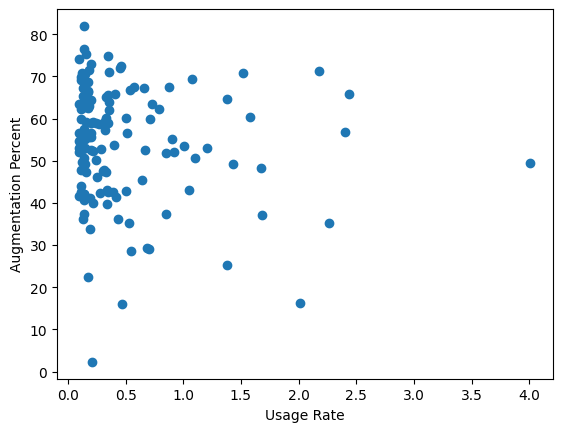

In [19]:
plt.scatter(non_zero_usage['Usage Rate'], non_zero_usage['Augmentation Percent'])
plt.xlabel('Usage Rate')
plt.ylabel('Augmentation Percent')

Text(0, 0.5, 'Augmentation Percent')

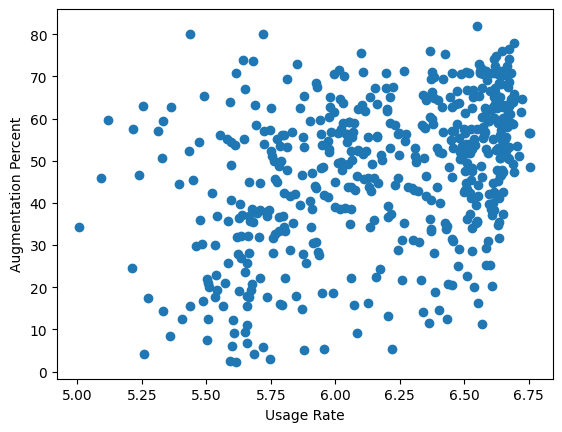

In [20]:
plt.scatter(ai_measurements_df['AIOE'], ai_measurements_df['Augmentation Percent'])
plt.xlabel('Usage Rate')
plt.ylabel('Augmentation Percent')